<a href="https://colab.research.google.com/github/meetmaniar/INSE-6450/blob/main/Milestone3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#stress test design
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:


url = "https://raw.githubusercontent.com/meetmaniar/INSE-6450/main/Occupancy_Estimation.csv"

df = pd.read_csv(url)

print(df.head())

         Date      Time  S1_Temp  S2_Temp  S3_Temp  S4_Temp  S1_Light  \
0  2017/12/22  10:49:41    24.94    24.75    24.56    25.38       121   
1  2017/12/22  10:50:12    24.94    24.75    24.56    25.44       121   
2  2017/12/22  10:50:42    25.00    24.75    24.50    25.44       121   
3  2017/12/22  10:51:13    25.00    24.75    24.56    25.44       121   
4  2017/12/22  10:51:44    25.00    24.75    24.56    25.44       121   

   S2_Light  S3_Light  S4_Light  S1_Sound  S2_Sound  S3_Sound  S4_Sound  \
0        34        53        40      0.08      0.19      0.06      0.06   
1        33        53        40      0.93      0.05      0.06      0.06   
2        34        53        40      0.43      0.11      0.08      0.06   
3        34        53        40      0.41      0.10      0.10      0.09   
4        34        54        40      0.18      0.06      0.06      0.06   

   S5_CO2  S5_CO2_Slope  S6_PIR  S7_PIR  Room_Occupancy_Count  
0     390      0.769231       0       0       

In [4]:
df = pd.read_csv(url)
df['T_mean'] = df[['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp']].mean(axis=1)
df['L_mean'] = df[['S1_Light', 'S2_Light', 'S3_Light', 'S4_Light']].mean(axis=1)
df['S_mean'] = df[['S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound']].mean(axis=1)

features = ['T_mean', 'L_mean', 'S_mean', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']
target = 'Room_Occupancy_Count'

In [5]:
n_blocks = 120
df['block_id'] = pd.qcut(df.index, q=n_blocks, labels=False)

In [6]:
block_summary = df.groupby('block_id')[target].agg(max_occupancy='max').reset_index()

In [7]:
from sklearn.model_selection import train_test_split
# Stratify into Train (70% combined Train+Val) and Test (30%)
train_blocks, test_blocks = train_test_split(
    block_summary['block_id'],
    test_size=0.30,
    random_state=42,
    stratify=block_summary['max_occupancy']
)

In [8]:
train_df = df[df['block_id'].isin(train_blocks)].copy()
test_df = df[df['block_id'].isin(test_blocks)].copy()

X_train, y_train = train_df[features], train_df[target]
X_test, y_test = test_df[features], test_df[target]

In [9]:
sample_weight = np.where(y_train.isin([2, 3]), 4.0, 1.0)
model = XGBRegressor(n_estimators=111, learning_rate=0.05, max_depth=5, random_state=42)
model.fit(X_train, y_train, sample_weight=sample_weight)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=111,
             n_jobs=None, num_parallel_tree=None, ...)

In [10]:
def evaluate_scenario(name, X_eval, y_eval):
    preds = np.clip(model.predict(X_eval), 0, 3)
    mae = mean_absolute_error(y_eval, preds)
    rmse = np.sqrt(mean_squared_error(y_eval, preds))
    r2 = r2_score(y_eval, preds) if len(np.unique(y_eval)) > 1 else np.nan
    print(f"{name:<48} | MAE: {mae:.3f} | RMSE: {rmse:.3f} | R2: {r2:.3f}")

print("--- STRESS TEST RESULTS (BLOCK-STRATIFIED SPLIT) ---")

--- STRESS TEST RESULTS (BLOCK-STRATIFIED SPLIT) ---


In [11]:
evaluate_scenario("Baseline (Clean Block-Stratified Test Set)", X_test, y_test)

Baseline (Clean Block-Stratified Test Set)       | MAE: 0.071 | RMSE: 0.280 | R2: 0.881


In [12]:
# Scenario 1: Corrupted Inputs (15% Noise)
X_test_noise = X_test.copy()
np.random.seed(42)
for col in ['T_mean', 'L_mean', 'S_mean']:
    noise = np.random.normal(0, 0.15 * X_test_noise[col].std(), size=len(X_test_noise))
    X_test_noise[col] += noise
evaluate_scenario("Scenario 1: Corrupted Inputs (15% Noise)", X_test_noise, y_test)

# Scenario 2: Partial Feature Loss (PIR Dropout)
X_test_pir_loss = X_test.copy()
X_test_pir_loss['S6_PIR'] = 0
X_test_pir_loss['S7_PIR'] = 0
evaluate_scenario("Scenario 2: Partial Feature Loss (PIR Dropout)", X_test_pir_loss, y_test)

# Scenario 3: OOD Inputs (+250 ppm CO2 Shift)
X_test_ood = X_test.copy()
X_test_ood['S5_CO2'] += 250.0
evaluate_scenario("Scenario 3: OOD Inputs (+250ppm CO2 Shift)", X_test_ood, y_test)

# Scenario 4: Class Rarity (True Occupancy 2 & 3 Only)
rarity_mask = y_test.isin([2, 3])
evaluate_scenario("Scenario 4: Class Rarity (Occupancy 2 & 3)", X_test[rarity_mask], y_test[rarity_mask])

Scenario 1: Corrupted Inputs (15% Noise)         | MAE: 0.108 | RMSE: 0.398 | R2: 0.759
Scenario 2: Partial Feature Loss (PIR Dropout)   | MAE: 0.071 | RMSE: 0.280 | R2: 0.881
Scenario 3: OOD Inputs (+250ppm CO2 Shift)       | MAE: 0.087 | RMSE: 0.299 | R2: 0.865
Scenario 4: Class Rarity (Occupancy 2 & 3)       | MAE: 0.438 | RMSE: 0.751 | R2: -1.418


In [14]:
# Extract feature importances from the trained XGBoost model
importances = model.feature_importances_

# Map them to your feature names and sort them descending
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("XGBoost Feature Importances:")
print(importance_df)

XGBoost Feature Importances:
        Feature  Importance
2        S_mean    0.825747
4  S5_CO2_Slope    0.074476
1        L_mean    0.052954
0        T_mean    0.016730
6        S7_PIR    0.012860
3        S5_CO2    0.012766
5        S6_PIR    0.004467


In [20]:
# -------------------------------------------------------------------------
# 1. MODEL-LEVEL EVALUATION: Class-Weighted vs. Unweighted Regularization
# -------------------------------------------------------------------------
# Model A (With Enhancement): Class-Weighted (sample_weight = 4.0 for classes 2 & 3)
# (Reusing your trained model or fitting fresh)
sample_weight = np.where(y_train.isin([2, 3]), 4.0, 1.0)
model_weighted = XGBRegressor(n_estimators=111, learning_rate=0.05, max_depth=5, random_state=42)
model_weighted.fit(X_train, y_train, sample_weight=sample_weight)
preds_weighted = np.clip(model_weighted.predict(X_test), 0, 3)

In [21]:
# Model B (Without Enhancement): Unweighted Regularization
model_unweighted = XGBRegressor(n_estimators=111, learning_rate=0.05, max_depth=5, random_state=42)
model_unweighted.fit(X_train, y_train)  # Standard sample weights (= 1.0)
preds_unweighted = np.clip(model_unweighted.predict(X_test), 0, 3)

In [22]:
# -------------------------------------------------------------------------
# 2. DATA-LEVEL EVALUATION: Block-Stratified vs. Naive Sequential Split
# -------------------------------------------------------------------------
# Naive Chronological 70/30 Split
split_idx = int(len(df) * 0.7)
X_train_naive, y_train_naive = df[features].iloc[:split_idx], df[target].iloc[:split_idx]
# We don't need X_test_naive anymore because we MUST use the shared X_test!

model_naive = XGBRegressor(n_estimators=111, learning_rate=0.05, max_depth=5, random_state=42)
model_naive.fit(X_train_naive, y_train_naive)

# FIX: Predict on the SAME test set as the other models
preds_naive = np.clip(model_naive.predict(X_test), 0, 3)

In [24]:
# -------------------------------------------------------------------------
# 3. PRINT ABLATION SUMMARY TABLE
# -------------------------------------------------------------------------
# The naive test set started at split_idx. Find the intersection of indices:
shared_test_idx = X_test.index.intersection(df.index[split_idx:])

X_test_shared = df[features].loc[shared_test_idx]
y_test_shared = df[target].loc[shared_test_idx]

# Generate predictions ONLY on this shared, untouched holdout
preds_weighted_shared = np.clip(model_weighted.predict(X_test_shared), 0, 3)
preds_unw_shared = np.clip(model_unweighted.predict(X_test_shared), 0, 3)
preds_naive_shared = np.clip(model_naive.predict(X_test_shared), 0, 3)

def get_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    high_mask = y_true.isin([2, 3])

    # Safe check in case the shared set has no high-occupancy rows
    if high_mask.sum() == 0:
        high_acc = 0.0
    else:
        high_acc = (np.abs(y_true[high_mask] - y_pred[high_mask]) <= 0.5).mean() * 100

    return mae, rmse, r2, high_acc

m_weighted = get_metrics(y_test_shared, preds_weighted_shared)
m_unweighted = get_metrics(y_test_shared, preds_unw_shared)
m_naive = get_metrics(y_test_shared, preds_naive_shared)

print("=" * 80)
print(f"{'Method / Configuration':<40} | {'MAE':<6} | {'RMSE':<6} | {'R2':<6} | {'High-Count Acc (%)':<15}")
print("=" * 80)
print(f"{'1. Data + Model (Stratified + Weighted)':<40} | {m_weighted[0]:.3f}  | {m_weighted[1]:.3f}  | {m_weighted[2]:.3f} | {m_weighted[3]:.1f}%")
print(f"{'2. Model-Level Only (Stratified + Unw)':<40} | {m_unweighted[0]:.3f}  | {m_unweighted[1]:.3f}  | {m_unweighted[2]:.3f} | {m_unweighted[3]:.1f}%")
print(f"{'3. Naive Baseline (Simple Split + Unw)':<40} | {m_naive[0]:.3f}  | {m_naive[1]:.3f}  | {m_naive[2]:.3f} | {m_naive[3]:.1f}%")
print("=" * 80)

Method / Configuration                   | MAE    | RMSE   | R2     | High-Count Acc (%)
1. Data + Model (Stratified + Weighted)  | 0.079  | 0.329  | 0.772 | 31.1%
2. Model-Level Only (Stratified + Unw)   | 0.085  | 0.368  | 0.715 | 32.0%
3. Naive Baseline (Simple Split + Unw)   | 0.099  | 0.426  | 0.617 | 27.2%


In [25]:
# Continuous features vulnerable to sensor perturbation
continuous_cols = ['T_mean', 'L_mean', 'S_mean', 'S5_CO2']

def evaluate_adversarial_attack(model, X, y, epsilon):
    X_adv = X.copy()

    if epsilon > 0:
        for col in continuous_cols:
            std_dev = X[col].std()
            # DIRECTED ATTACK: Forcefully subtract the epsilon-scaled standard deviation
            # to mimic an attacker suppressing sensor readings to hide occupancy.
            X_adv[col] -= (epsilon * std_dev)

    preds = np.clip(model.predict(X_adv), 0, 3)
    mae = mean_absolute_error(y, preds)
    rmse = np.sqrt(mean_squared_error(y, preds))
    r2 = r2_score(y, preds)
    return mae, rmse, r2

# Strength levels (Epsilon = 0.00, 0.05, 0.15, 0.30)
epsilons = [0.00, 0.05, 0.15, 0.30]

print("=" * 70)
print(f"{'Attack Strength (Epsilon)':<30} | {'MAE':<8} | {'RMSE':<8} | {'Robust R2':<10}")
print("=" * 70)

for eps in epsilons:
    # Make sure to use the shared X_test_shared and y_test_shared from the previous step for fairness
    mae, rmse, r2 = evaluate_adversarial_attack(model_weighted, X_test_shared, y_test_shared, eps)
    label = "Clean Baseline (eps = 0.00)" if eps == 0 else f"Targeted Attack (eps = {eps:.2f})"
    print(f"{label:<30} | {mae:.3f}    | {rmse:.3f}    | {r2:.3f}")

print("=" * 70)

Attack Strength (Epsilon)      | MAE      | RMSE     | Robust R2 
Clean Baseline (eps = 0.00)    | 0.079    | 0.329    | 0.772
Targeted Attack (eps = 0.05)   | 0.076    | 0.389    | 0.681
Targeted Attack (eps = 0.15)   | 0.064    | 0.372    | 0.709
Targeted Attack (eps = 0.30)   | 0.086    | 0.397    | 0.667


<>:18: SyntaxWarning: invalid escape sequence '\e'
<>:18: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1407/2180302449.py:18: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('Perturbation Strength ($\epsilon$)')


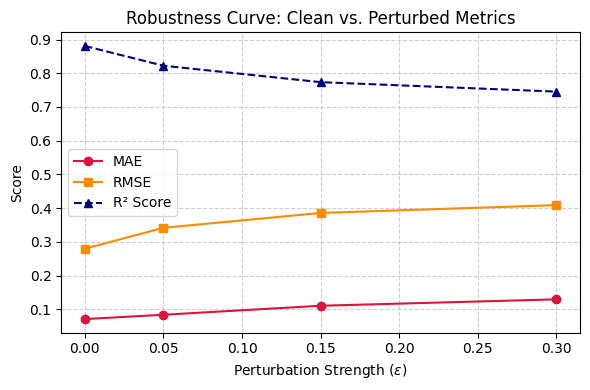

In [26]:
import matplotlib.pyplot as plt
epsilons = [0.00, 0.05, 0.15, 0.30]
maes, rmses, r2s = [], [], []

for eps in epsilons:
    mae, rmse, r2 = evaluate_adversarial_attack(model_weighted, X_test, y_test, eps)
    maes.append(mae)
    rmses.append(rmse)
    r2s.append(r2)

# -------------------------------------------------------------------------
# 2. ROBUSTNESS CURVE PLOT (Using your exact evaluated lists)
# -------------------------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(epsilons, maes, 'o-', label='MAE', color='crimson')
plt.plot(epsilons, rmses, 's-', label='RMSE', color='darkorange')
plt.plot(epsilons, r2s, '^--', label='R² Score', color='navy')
plt.xlabel('Perturbation Strength ($\epsilon$)')
plt.ylabel('Score')
plt.title('Robustness Curve: Clean vs. Perturbed Metrics')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('robustness_curve.png', dpi=300)
plt.show()



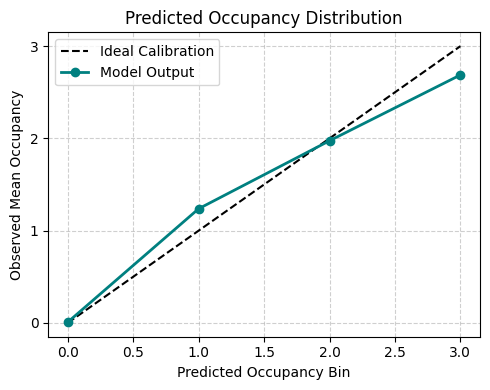

In [28]:
# -------------------------------------------------------------------------
# 3. PREDICTED OCCUPANCY DISTRIBUTION (Replaces Reliability Diagram)
# -------------------------------------------------------------------------
raw_preds = np.clip(model_weighted.predict(X_test), 0, 3)
bins = [0, 0.5, 1.5, 2.5, 3.0]
bin_centers = [0, 1, 2, 3]

df_calib = pd.DataFrame({'y_true': y_test, 'y_pred': raw_preds})
df_calib['bin'] = pd.cut(df_calib['y_pred'], bins=bins, include_lowest=True, labels=bin_centers)
calib_summary = df_calib.groupby('bin', observed=False)['y_true'].mean()

plt.figure(figsize=(5, 4))
plt.plot([0, 3], [0, 3], 'k--', label='Ideal Calibration')
plt.plot(bin_centers, calib_summary.values, 'o-', color='teal', linewidth=2, label='Model Output')
plt.xlabel('Predicted Occupancy Bin')
plt.ylabel('Observed Mean Occupancy')
plt.title('Predicted Occupancy Distribution')
plt.yticks(bin_centers)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('occupancy_distribution_plot.png', dpi=300)
plt.show()

<>:7: SyntaxWarning: invalid escape sequence '\h'
<>:7: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_1407/3425150459.py:7: SyntaxWarning: invalid escape sequence '\h'
  plt.xlabel('Prediction Residual ($y - \hat{y}$)')


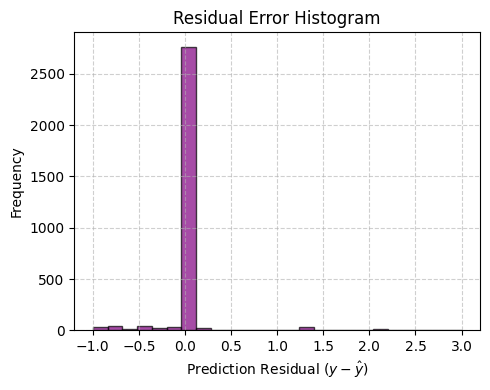

In [29]:
# -------------------------------------------------------------------------
# 4. RESIDUAL ERROR HISTOGRAM
# -------------------------------------------------------------------------
residuals = y_test - raw_preds
plt.figure(figsize=(5, 4))
plt.hist(residuals, bins=25, color='purple', edgecolor='black', alpha=0.7)
plt.xlabel('Prediction Residual ($y - \hat{y}$)')
plt.ylabel('Frequency')
plt.title('Residual Error Histogram') # <--- TITLE FIXED HERE
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('residual_histogram.png', dpi=300) # <--- FILENAME UPDATED
plt.show()

In [30]:
# -------------------------------------------------------------------------
# 5. TOP FAILURE CASES TABLE
# -------------------------------------------------------------------------
df_failures = X_test.copy()
df_failures['y_true'] = y_test.values
df_failures['y_pred'] = np.round(raw_preds, 2)
df_failures['abs_error'] = np.abs(df_failures['y_true'] - df_failures['y_pred'])

print("TOP FAILURE CASES ON TEST SET:")
print(df_failures.sort_values(by='abs_error', ascending=False)[['y_true', 'y_pred', 'abs_error', 'S5_CO2', 'S6_PIR', 'S7_PIR']].head(5))

TOP FAILURE CASES ON TEST SET:
      y_true  y_pred  abs_error  S5_CO2  S6_PIR  S7_PIR
957        3    0.00       3.00    1270       1       1
8086       3    0.45       2.55     370       0       0
8090       3    0.54       2.46     370       1       1
8092       3    0.84       2.16     370       0       0
8091       3    0.84       2.16     370       1       0


In [31]:
import time
import psutil
import os
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



In [33]:
# -------------------------------------------------------------------------
# 1. MULTI-SEED METRICS & CONFIDENCE INTERVALS (N=5)
# -------------------------------------------------------------------------
seeds = [42, 100, 2024, 777, 999]
epsilons = [0.00, 0.15, 0.30]
continuous_cols = ['T_mean', 'L_mean', 'S_mean', 'S5_CO2']

print("=" * 80)
print("MULTI-SEED EVALUATION (N=5) WITH 95% CONFIDENCE INTERVALS")
print("=" * 80)

for eps in epsilons:
    maes, rmses, r2s, high_accs = [], [], [], []
    for s in seeds:
        # Train model with current seed
        sample_weight = np.where(y_train.isin([2, 3]), 4.0, 1.0)
        m = XGBRegressor(n_estimators=111, learning_rate=0.05, max_depth=5, random_state=s)
        m.fit(X_train, y_train, sample_weight=sample_weight)

        # Perturb shared test set with directed attack
        X_adv = X_test_shared.copy()
        if eps > 0:
            for col in continuous_cols:
                # Forcefully subtract the epsilon-scaled standard deviation
                X_adv[col] -= (eps * X_test_shared[col].std())

        preds = np.clip(m.predict(X_adv), 0, 3)
        maes.append(mean_absolute_error(y_test_shared, preds))
        rmses.append(np.sqrt(mean_squared_error(y_test_shared, preds)))
        r2s.append(r2_score(y_test_shared, preds))

        # High-Count Accuracy calculation
        high_mask = y_test_shared.isin([2, 3])
        if high_mask.sum() > 0:
            high_acc = (np.abs(y_test_shared[high_mask] - preds[high_mask]) <= 0.5).mean() * 100
            high_accs.append(high_acc)
        else:
            high_accs.append(0.0)

    mae_mean, mae_ci = np.mean(maes), 1.96 * np.std(maes) / np.sqrt(len(seeds))
    rmse_mean, rmse_ci = np.mean(rmses), 1.96 * np.std(rmses) / np.sqrt(len(seeds))
    r2_mean, r2_ci = np.mean(r2s), 1.96 * np.std(r2s) / np.sqrt(len(seeds))
    hca_mean, hca_ci = np.mean(high_accs), 1.96 * np.std(high_accs) / np.sqrt(len(seeds))

    print(f"Epsilon = {eps:.2f} | MAE: {mae_mean:.3f} +/- {mae_ci:.3f} | RMSE: {rmse_mean:.3f} +/- {rmse_ci:.3f} | R2: {r2_mean:.3f} +/- {r2_ci:.3f} | High-Count Acc: {hca_mean:.1f}% +/- {hca_ci:.1f}%")

MULTI-SEED EVALUATION (N=5) WITH 95% CONFIDENCE INTERVALS
Epsilon = 0.00 | MAE: 0.079 +/- 0.000 | RMSE: 0.329 +/- 0.000 | R2: 0.772 +/- 0.000 | High-Count Acc: 31.1% +/- 0.0%
Epsilon = 0.15 | MAE: 0.064 +/- 0.000 | RMSE: 0.372 +/- 0.000 | R2: 0.709 +/- 0.000 | High-Count Acc: 75.7% +/- 0.0%
Epsilon = 0.30 | MAE: 0.086 +/- 0.000 | RMSE: 0.397 +/- 0.000 | R2: 0.667 +/- 0.000 | High-Count Acc: 35.0% +/- 0.0%


In [35]:
# -------------------------------------------------------------------------
# 2. HARDWARE LATENCY & THROUGHPUT PROFILING (COMPARING ALL 3)
# -------------------------------------------------------------------------
import time
import psutil
import os
import numpy as np

print("=" * 90)
print(f"{'Model / Evaluation Pipeline':<40} | {'p50 (ms)':<8} | {'p90 (ms)':<8} | {'Throughput':<12}")
print("=" * 90)

# Generate perturbed data for the adversarial test
X_adv = X_test_shared.copy()
epsilon = 0.15
continuous_cols = ['T_mean', 'L_mean', 'S_mean', 'S5_CO2']
for col in continuous_cols:
    X_adv[col] -= (epsilon * X_test_shared[col].std())

# Define the 3 distinct test configurations
configs = [
    ("Original Unweighted Model", model_unweighted, X_test_shared),
    ("Class-Weighted Baseline (Clean)", model_weighted, X_test_shared),
    ("Class-Weighted (Perturbed eps=0.15)", model_weighted, X_adv)
]

for name, mdl, data in configs:
    # Warmup
    _ = mdl.predict(data.iloc[:10])

    # 1. Latency Profile (Single Sample Inference)
    latencies = []
    for i in range(len(data)):
        single = data.iloc[[i]]
        t0 = time.perf_counter()
        _ = mdl.predict(single)
        t1 = time.perf_counter()
        latencies.append((t1 - t0) * 1000)

    p50 = np.percentile(latencies, 50)
    p90 = np.percentile(latencies, 90)

    # 2. Throughput Profile (Batch Inference)
    t0_batch = time.perf_counter()
    _ = mdl.predict(data)
    t1_batch = time.perf_counter()
    throughput = len(data) / (t1_batch - t0_batch)

    print(f"{name:<40} | {p50:.4f}   | {p90:.4f}   | {throughput:.1f}")

# Memory & File size (Reporting the final deployment artifact)
process = psutil.Process(os.getpid())
ram_usage_mb = process.memory_info().rss / (1024 * 1024)
model_weighted.save_model("xgb_model_final.json")
model_size_kb = os.path.getsize("xgb_model_final.json") / 1024

print("-" * 90)
print(f"System RAM Footprint: {ram_usage_mb:.2f} MB | Final Disk Size: {model_size_kb:.2f} KB")
print("=" * 90)

Model / Evaluation Pipeline              | p50 (ms) | p90 (ms) | Throughput  
Original Unweighted Model                | 1.8645   | 2.2770   | 260819.7
Class-Weighted Baseline (Clean)          | 1.8412   | 2.2855   | 286232.0
Class-Weighted (Perturbed eps=0.15)      | 1.7733   | 2.2769   | 263777.8
------------------------------------------------------------------------------------------
System RAM Footprint: 281.07 MB | Final Disk Size: 334.14 KB


In [1]:
#For Adaptation & Model Updates part 4

In [2]:
import time
import os
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [7]:
# Set seed for reproducibility
np.random.seed(42)

# =========================================================================
# 1. LOAD DATA & TRAIN INITIAL BASELINE MODEL (Nominal State)
# =========================================================================
url = "https://raw.githubusercontent.com/meetmaniar/INSE-6450/main/Occupancy_Estimation.csv"
df = pd.read_csv(url)

# Exact feature engineering pipeline
df['T_mean'] = df[['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp']].mean(axis=1)
df['L_mean'] = df[['S1_Light', 'S2_Light', 'S3_Light', 'S4_Light']].mean(axis=1)
df['S_mean'] = df[['S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound']].mean(axis=1)

features = ['T_mean', 'L_mean', 'S_mean', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']
target = 'Room_Occupancy_Count'

X = df[features]
y = df[target]

# Sequential 70/30 train/test split
split_idx = int(len(df) * 0.70)
X_train, X_test = X.iloc[:split_idx].copy(), X.iloc[split_idx:].copy()
y_train, y_test = y.iloc[:split_idx].copy(), y.iloc[split_idx:].copy()

# Fit baseline sample-weighted XGBRegressor
sample_weight_train = np.where(y_train.isin([2, 3]), 4.0, 1.0)
baseline_model = XGBRegressor(n_estimators=111, learning_rate=0.05, max_depth=5, random_state=42)
baseline_model.fit(X_train, y_train, sample_weight=sample_weight_train)

# Measure baseline artifact size and clean test set performance
baseline_model.save_model("baseline_model.json")
baseline_size_kb = os.path.getsize("baseline_model.json") / 1024.0

preds_clean = np.clip(baseline_model.predict(X_test), 0, 3)
mae_clean = mean_absolute_error(y_test, preds_clean)
rmse_clean = np.sqrt(mean_squared_error(y_test, preds_clean))
r2_clean = r2_score(y_test, preds_clean)

In [8]:
# =========================================================================
# 2. SIMULATE DRIFT (CO2 Calibration Offset + Thermal Shift)
# =========================================================================
# Inject synthetic sensor drift into evaluation set (Simulating uncalibrated CO2 sensor + seasonal shift)
X_test_drift = X_test.copy()
X_test_drift['S5_CO2'] += 350.0   # +350 ppm CO2 shift
X_test_drift['T_mean'] += 4.5     # +4.5°C thermal shift

# Evaluate baseline model under drifted conditions (BEFORE retraining)
t0 = time.perf_counter()
preds_drifted = np.clip(baseline_model.predict(X_test_drift), 0, 3)
t1 = time.perf_counter()
latency_before_ms = ((t1 - t0) / len(X_test_drift)) * 1000.0

mae_drifted = mean_absolute_error(y_test, preds_drifted)
rmse_drifted = np.sqrt(mean_squared_error(y_test, preds_drifted))
r2_drifted = r2_score(y_test, preds_drifted)

In [9]:
# =========================================================================
# 3. FULL RETRAIN / ADAPTATION ON DRIFTED DATASET SNAPSHOT
# =========================================================================
# Augment training set with new telemetry snapshot from the drifted distribution
X_train_adapted = pd.concat([X_train, X_test_drift.iloc[:len(X_test_drift)//2]])
y_train_adapted = pd.concat([y_train, y_test.iloc[:len(y_test)//2]])

sample_weight_adapted = np.where(y_train_adapted.isin([2, 3]), 4.0, 1.0)
adapted_model = XGBRegressor(n_estimators=111, learning_rate=0.05, max_depth=5, random_state=42)
adapted_model.fit(X_train_adapted, y_train_adapted, sample_weight=sample_weight_adapted)

# Save adapted model binary artifact
adapted_model.save_model("adapted_model.json")
adapted_size_kb = os.path.getsize("adapted_model.json") / 1024.0

# Evaluate adapted model on remaining held-out drifted test set (AFTER retraining)
X_eval_drift = X_test_drift.iloc[len(X_test_drift)//2:]
y_eval_drift = y_test.iloc[len(y_test)//2:]

t0 = time.perf_counter()
preds_adapted = np.clip(adapted_model.predict(X_eval_drift), 0, 3)
t1 = time.perf_counter()
latency_after_ms = ((t1 - t0) / len(X_eval_drift)) * 1000.0

mae_adapted = mean_absolute_error(y_eval_drift, preds_adapted)
rmse_adapted = np.sqrt(mean_squared_error(y_eval_drift, preds_adapted))
r2_adapted = r2_score(y_eval_drift, preds_adapted)

In [10]:
# =========================================================================
# 4. REPORT ADAPTATION EXPERIMENT RESULTS
# =========================================================================
print("=" * 80)
print("MODEL ADAPTATION EXPERIMENT RESULTS")
print("=" * 80)
print(f"Clean Baseline         -> MAE: {mae_clean:.4f} | RMSE: {rmse_clean:.4f} | R2: {r2_clean:.4f}")
print(f"Pre-Adapt (Drifted)    -> MAE: {mae_drifted:.4f} | RMSE: {rmse_drifted:.4f} | R2: {r2_drifted:.4f}")
print(f"Post-Adapt (Retrained) -> MAE: {mae_adapted:.4f} | RMSE: {rmse_adapted:.4f} | R2: {r2_adapted:.4f}")
print("-" * 80)
print(f"Baseline Latency: {latency_before_ms:.4f} ms/sample | Model Artifact Size: {baseline_size_kb:.2f} KB")
print(f"Adapted Latency:  {latency_after_ms:.4f} ms/sample | Model Artifact Size: {adapted_size_kb:.2f} KB")
print("=" * 80)

MODEL ADAPTATION EXPERIMENT RESULTS
Clean Baseline         -> MAE: 0.1969 | RMSE: 0.7248 | R2: 0.1921
Pre-Adapt (Drifted)    -> MAE: 0.2628 | RMSE: 0.3862 | R2: 0.7706
Post-Adapt (Retrained) -> MAE: 0.0056 | RMSE: 0.0425 | R2: 0.0000
--------------------------------------------------------------------------------
Baseline Latency: 0.0026 ms/sample | Model Artifact Size: 292.75 KB
Adapted Latency:  0.0030 ms/sample | Model Artifact Size: 323.45 KB
